# Where are the targets lost? — template/ranking/NMS diagnosis

Compare the same 120 validation images, 12 geometries, half strides, 32 grayscale histogram bins, slide max-denominator distance, NMS IoU 0.3 and max 100 detections/class. Four configurations isolate two changes:

1. One average masked template/class vs **8 actual representative masked templates/class**.
2. Keep top 1000 vs top 10000 scored windows/class before NMS.

The bank uses deterministic farthest-first selection within Vistas role=template objects, starting with the template closest to the class mean. Selected crops are saved in `selected_templates.csv`. It is a bounded representative bank, not exhaustive nearest matching over all 290 templates. Selection never uses NYC images or annotations. Held-out Vistas validation-role crops and NYC test data are untouched.

Scores are minimum distance to any template in the class bank. NMS and threshold grids remain fixed between configurations. Class thresholds are selected on validation, so resulting F1 is a development score, not final held-out performance. Source annotations remain uncorrected and duplicates are retained; one invalid zero-width box is excluded.


In [1]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.patches import Rectangle
from IPython.display import display
COLAB=Path('/content/drive/MyDrive/ComputerVision/Midterm/midterm-csc74030-main')
LOCAL=Path('/Users/yingying/Downloads/midterm-csc74030-main')
PROJECT=COLAB if COLAB.is_dir() else LOCAL
FOLDER=PROJECT/'template_diagnostics'
if (Path.cwd()/'diagnose.py').is_file():FOLDER=Path.cwd()
sys.path.insert(0,str(FOLDER))
from diagnose import run
RESULTS=FOLDER/'results'
RUN_AGAIN=False
if RUN_AGAIN:run(PROJECT,RESULTS)
summary=json.loads((RESULTS/'summary.json').read_text())
survival=pd.read_csv(RESULTS/'survival.csv')
ranks=pd.read_csv(RESULTS/'ranks.csv')
metrics=pd.read_csv(RESULTS/'metrics.csv')
predictions=json.loads((RESULTS/'predictions.json').read_text())
print('Images:',summary['images'],'Valid source boxes:',summary['valid_gt'])


Images: 120 Valid source boxes: 228


## 1. Survival through each step

A source box survives a stage if at least one same-class candidate overlaps it with IoU>=0.5. This is an **independent coverage diagnostic**, not one-to-one detector recall: one candidate could cover multiple annotation rows. Never use these GT checks to guide inference. All stages use the same GT denominator (228 overall).

`all_windows`: geometric coverage before any template scoring. `top1000/top10000`: coverage after score ranking. `post_nms_before_cap`: NMS suppression with the 1000-window input, before final max-100 cap. `post_nms_cap100`: retained detections before threshold. `post_threshold`: selected validation distance threshold. Top10000 branch does not compute an unlimited-NMS diagnostic; its NMS and final cap are measured together.


stage,all_windows,top1000,top10000,post_nms_before_cap,post_nms_cap100,post_threshold
method,,,,,,
average_top1000,0.7895,0.1272,NaN,0.0702,0.0263,0.0263
average_top10000,0.7895,NaN,0.4781,NaN,0.0263,0.0263
bank8_top1000,0.7895,0.0088,NaN,0.0044,0.0000,0.0000
bank8_top10000,0.7895,NaN,0.2851,NaN,0.0000,0.0000


,method,stage,covered,gt
0,average_top1000,all_windows,180,228
1,average_top1000,post_nms_before_cap,16,228
2,average_top1000,post_nms_cap100,6,228
3,average_top1000,post_threshold,6,228
4,average_top1000,top1000,29,228
5,average_top10000,all_windows,180,228
6,average_top10000,post_nms_cap100,6,228
7,average_top10000,post_threshold,6,228
8,average_top10000,top10000,109,228
9,bank8_top1000,all_windows,180,228


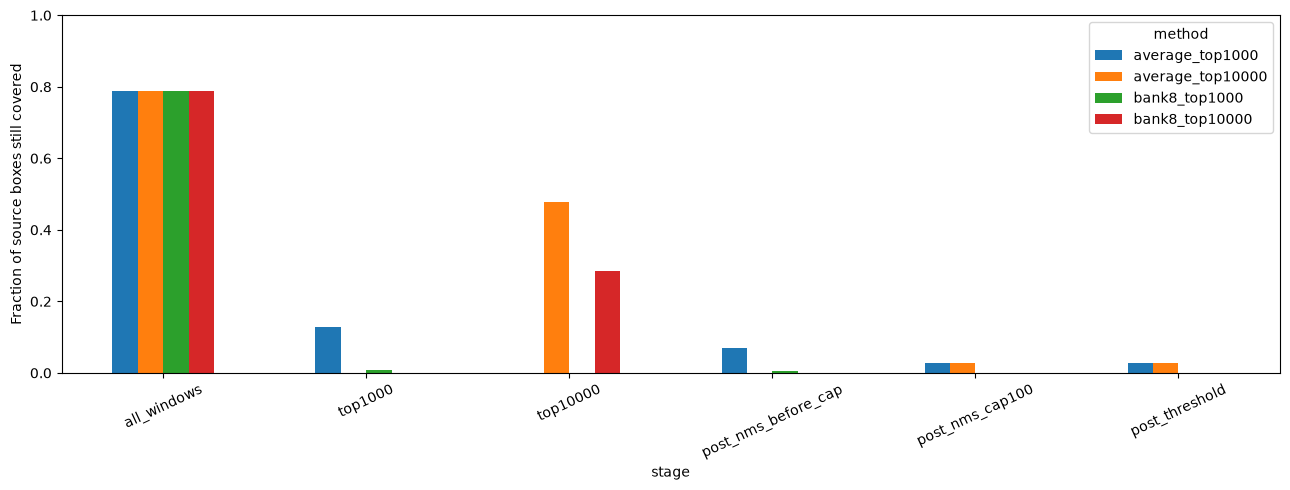

,method,cls,stage,covered,gt,coverage
0,average_top1000,cone,all_windows,117,152,0.7697
1,average_top1000,cone,post_nms_before_cap,12,152,0.0789
2,average_top1000,cone,post_nms_cap100,3,152,0.0197
3,average_top1000,cone,post_threshold,3,152,0.0197
4,average_top1000,cone,top1000,20,152,0.1316
5,average_top1000,sign,all_windows,63,76,0.8289
6,average_top1000,sign,post_nms_before_cap,4,76,0.0526
7,average_top1000,sign,post_nms_cap100,3,76,0.0395
8,average_top1000,sign,post_threshold,3,76,0.0395
9,average_top1000,sign,top1000,9,76,0.1184


In [2]:
stages=survival.groupby(['method','stage'])[['covered','gt']].sum().reset_index()
stages['coverage']=stages['covered']/stages['gt']
order=['all_windows','top1000','top10000','post_nms_before_cap','post_nms_cap100','post_threshold']
table=stages.pivot(index='method',columns='stage',values='coverage').reindex(columns=order)
display(table.round(4))
display(stages[['method','stage','covered','gt']])
table.T.plot.bar(figsize=(13,5),ylim=(0,1),rot=25)
plt.ylabel('Fraction of source boxes still covered');plt.tight_layout();plt.show()
by_class=survival.groupby(['method','cls','stage'])[['covered','gt']].sum().reset_index()
by_class['coverage']=by_class['covered']/by_class['gt']
display(by_class.round(4))


## 2. Best rank of a window that can cover each target

Rank 1 means the best template score in that image/class. Only geometrically coverable GT boxes have ranks. If the best covering window ranks below 1000 or 10000, the corresponding pre-NMS cutoff necessarily removes every window that could cover that annotation. Percentiles here are descriptive over source annotation rows.


In [3]:
coverable=ranks[ranks.geometrically_coverable].copy()
display(coverable.groupby(['mode','cls']).best_covering_rank.describe().round(2))
rank_coverage=coverable.groupby('mode').apply(
    lambda d: pd.Series({'coverable_boxes':len(d),
                         'fraction_best_rank_le_1000':(d.best_covering_rank<=1000).mean(),
                         'fraction_best_rank_le_10000':(d.best_covering_rank<=10000).mean()}),include_groups=False)
display(rank_coverage.round(4))


count      mean       std    min     25%      50%      75%  \
mode    cls                                                                
average cone  117.0  10606.27  12238.95  196.0  2124.0   5287.0  14427.0   
        sign   63.0  15470.94  19739.77   54.0  3219.5   8808.0  19486.0   
bank8   cone  117.0  19227.94  17300.39  727.0  7270.0  13789.0  24381.0   
        sign   63.0  24306.44  23081.74  373.0  6962.0  16285.0  33104.5   

                   max  
mode    cls             
average cone   56048.0  
        sign   98369.0  
bank8   cone   88395.0  
        sign  102850.0

,coverable_boxes,fraction_best_rank_le_1000,fraction_best_rank_le_10000
mode,,,
average,180.0,0.1611,0.6056
bank8,180.0,0.0111,0.3611


## 3. Actual object detection metrics and inference time

One-to-one class-matched IoU>=0.5 matching. Duplicate detections are false positives. Thresholds 0..2 in .05 steps are independently selected by class F1, with the same tie rule as the earlier baseline. Negative-image FP is reported separately. Diagnostic calculations, full-NMS diagnostic, threshold sweep and output writing are excluded from reported inference time; shared extraction and normal scoring/NMS are charged to each configuration. Single-run timings are machine-specific.


In [4]:
display(metrics[metrics.scope=='all'].round(6))
display(metrics[metrics.scope=='negative'][['method','fp']])
display(pd.Series(summary['seconds_per_image'],name='seconds_per_image').to_frame().round(4))
print('Selected thresholds:',summary['selected_thresholds'])
display(metrics[metrics.scope.isin(['cone_only','sign_only','both'])].round(6))


,method,scope,tp,fp,fn,precision,recall,f1
0,average_top1000,all,5,19631,223,0.000255,0.02193,0.000503
7,average_top10000,all,5,19631,223,0.000255,0.02193,0.000503
14,bank8_top1000,all,0,0,228,0.000000,0.00000,0.000000
21,bank8_top10000,all,0,0,228,0.000000,0.00000,0.000000


,method,fp
4,average_top1000,3280
11,average_top10000,3280
18,bank8_top1000,0
25,bank8_top10000,0


,seconds_per_image
average_top1000,0.1569
average_top10000,0.1897
bank8_top1000,0.1982
bank8_top10000,0.2312


Selected thresholds: {'average_top1000': {'cone': 0.4, 'sign': 0.25}, 'average_top10000': {'cone': 0.4, 'sign': 0.25}, 'bank8_top1000': {'cone': 0.0, 'sign': 0.0}, 'bank8_top10000': {'cone': 0.0, 'sign': 0.0}}


,method,scope,tp,fp,fn,precision,recall,f1
1,average_top1000,cone_only,1,6581,77,0.000152,0.012821,0.000300
2,average_top1000,sign_only,2,6994,54,0.000286,0.035714,0.000567
3,average_top1000,both,2,2776,92,0.000720,0.021277,0.001393
8,average_top10000,cone_only,1,6581,77,0.000152,0.012821,0.000300
9,average_top10000,sign_only,2,6994,54,0.000286,0.035714,0.000567
10,average_top10000,both,2,2776,92,0.000720,0.021277,0.001393
15,bank8_top1000,cone_only,0,0,78,0.000000,0.000000,0.000000
16,bank8_top1000,sign_only,0,0,56,0.000000,0.000000,0.000000
17,bank8_top1000,both,0,0,94,0.000000,0.000000,0.000000
22,bank8_top10000,cone_only,0,0,78,0.000000,0.000000,0.000000


## 4. Inspect predictions

Choose an image index. Green dashed outlines = source boxes. Red outlines = predictions after NMS and selected threshold. `MAX_DISPLAY` affects only plots. Grayscale image pixels and source data remain unchanged.


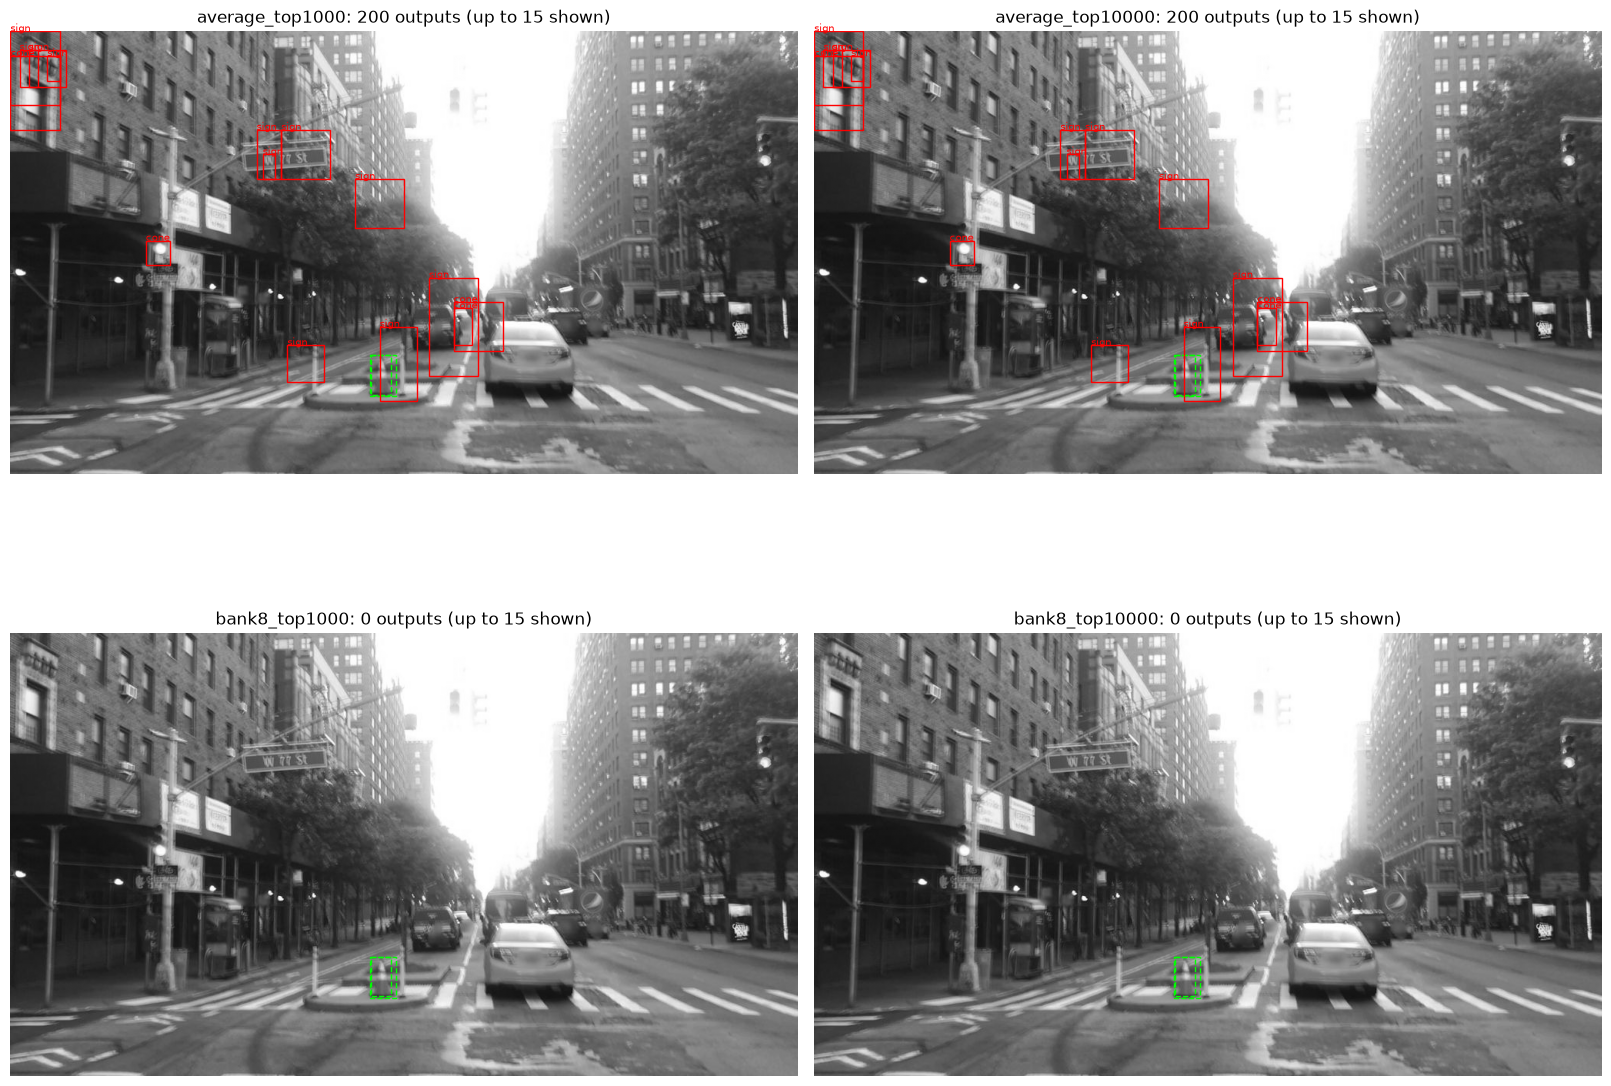

In [5]:
IMAGE_INDEX=0
MAX_DISPLAY=15
metadata=pd.read_csv(PROJECT/'Test Dataset/validation/images.csv')
annotations=pd.read_csv(PROJECT/'Test Dataset/validation/annotations.csv')
image=metadata.iloc[IMAGE_INDEX]
with Image.open(PROJECT/'Test Dataset/validation'/image['image']) as im:gray=np.array(im.convert('L'))
fig,axes=plt.subplots(2,2,figsize=(16,12),layout='constrained')
for ax,method in zip(axes.ravel(),summary['selected_thresholds']):
    ax.imshow(gray,cmap='gray',vmin=0,vmax=255)
    for _,r in annotations[annotations.image==image['image']].iterrows():
        if r.x1>r.x0 and r.y1>r.y0:
            ax.add_patch(Rectangle((r.x0,r.y0),r.x1-r.x0,r.y1-r.y0,fill=False,edgecolor='lime',linestyle='--'))
    detections=[]
    for cls in ['cone','sign']:
        detections.extend(dict(d,cls=cls) for d in predictions[image['image']][method][cls]
                          if d['distance']<=summary['selected_thresholds'][method][cls])
    for d in sorted(detections,key=lambda d:d['distance'])[:MAX_DISPLAY]:
        x0,y0,x1,y1=d['box']
        ax.add_patch(Rectangle((x0,y0),x1-x0,y1-y0,fill=False,edgecolor='red'))
        ax.text(x0,y0,d['cls'],color='red',fontsize=7)
    ax.set_title(f'{method}: {len(detections)} outputs (up to {MAX_DISPLAY} shown)');ax.axis('off')
plt.show()


## Limits and next decision

A loss in `all_windows` is geometric; loss at top-K is scoring/ranking; loss between top-K and NMS is suppression and/or the final detection cap; loss at threshold is the chosen operating point. These diagnostics identify where coverage disappears, not why brightness features rank a particular window poorly. A representative-template bank can recover variation lost by averaging, but may also match more backgrounds. Increasing top-K is a diagnostic intervention, not a guarantee of better precision.

Review README's measured results before choosing another experiment. Do not tune on test. This experiment intentionally keeps mask-only templates; testing full-crop templates would be a separate change, because it changes reference/background content.
